# Assignment 11: Matplotlib

## Task 1: Line Plot (Sales Trend)

In [6]:
import pandas as pd
import matplotlib.pyplot as plt



In [2]:
# crate data frame using kaggle walmart dataset
df=pd.read_csv("dataset_file/Walmart_Sales.csv")
print(df)

      Store        Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
0         1  05-02-2010    1643690.90             0        42.31       2.572   
1         1  12-02-2010    1641957.44             1        38.51       2.548   
2         1  19-02-2010    1611968.17             0        39.93       2.514   
3         1  26-02-2010    1409727.59             0        46.63       2.561   
4         1  05-03-2010    1554806.68             0        46.50       2.625   
...     ...         ...           ...           ...          ...         ...   
6430     45  28-09-2012     713173.95             0        64.88       3.997   
6431     45  05-10-2012     733455.07             0        64.89       3.985   
6432     45  12-10-2012     734464.36             0        54.47       4.000   
6433     45  19-10-2012     718125.53             0        56.47       3.969   
6434     45  26-10-2012     760281.43             0        58.85       3.882   

             CPI  Unemployment  
0     

Text(0, 0.5, 'Total Sales')

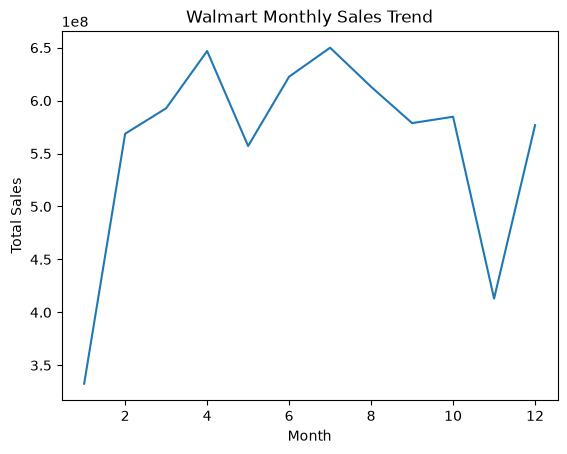

In [11]:
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
# Extract month number
df["Month"] = df["Date"].dt.month

# Calculate total sales for each month
monthly_sales = df.groupby("Month")["Weekly_Sales"].sum()

# Create line plot
plt.plot(monthly_sales.index, monthly_sales.values)

# Add title
plt.title("Walmart Monthly Sales Trend")

# Add X-axis label
plt.xlabel("Month")

# Add Y-axis label
plt.ylabel("Total Sales")


Text(0, 0.5, 'Weekly Sales')

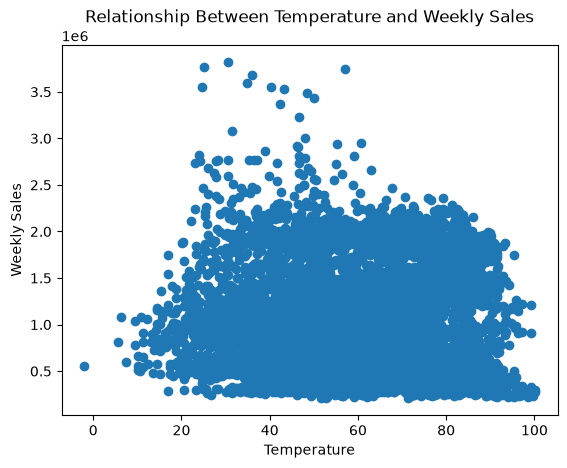

In [10]:
## Task 2: Scatter Plot

plt.scatter(df["Temperature"],df["Weekly_Sales"])
# Add title
plt.title("Relationship Between Temperature and Weekly Sales")

# Add X-axis label
plt.xlabel("Temperature")

# Add Y-axis label
plt.ylabel("Weekly Sales")



Text(0, 0.5, 'Total Sales')

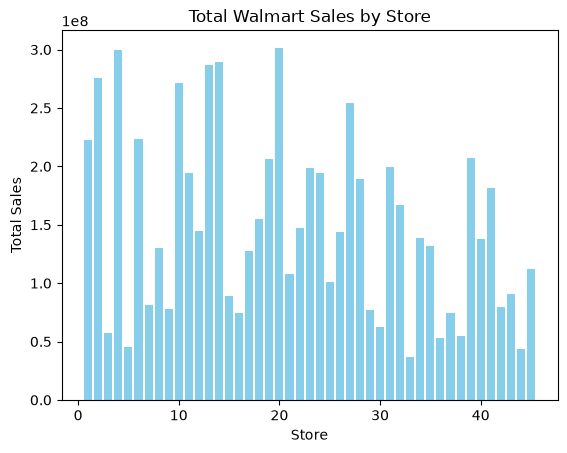

In [17]:
# Task 3: Bar Plot
## Total sales of each store
## Vertical Bar Chart
store_sales=df.groupby("Store")["Weekly_Sales"].sum()
plt.Figure(figsize=(12,6))
plt.bar(store_sales.index,store_sales.values,color="skyblue")
plt.title("Total Walmart Sales by Store")
plt.xlabel("Store")
plt.ylabel("Total Sales")


Text(0, 0.5, 'Store')

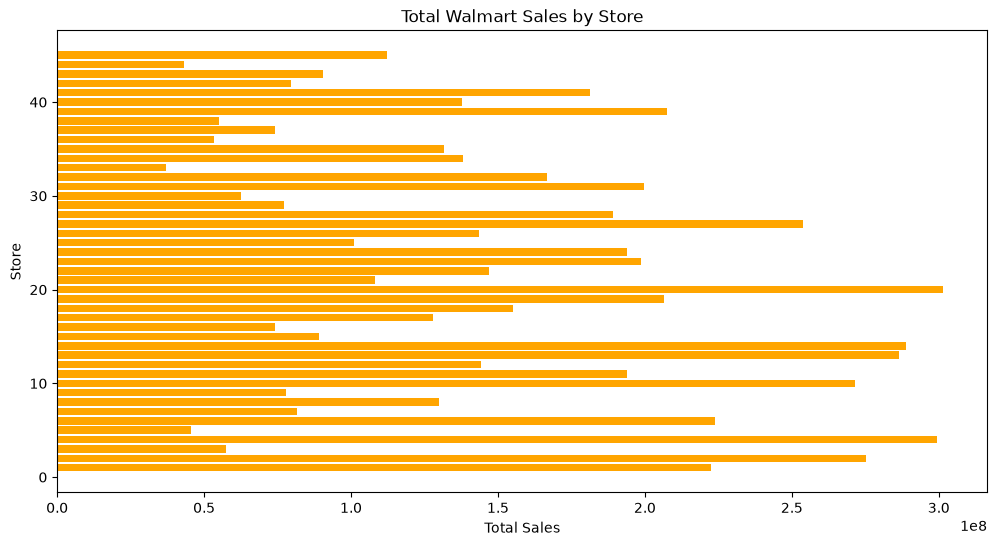

In [18]:
# Horizontal Chart
plt.figure(figsize=(12, 6))
plt.barh(store_sales.index, store_sales.values, color="orange")

plt.title("Total Walmart Sales by Store")
plt.xlabel("Total Sales")
plt.ylabel("Store")

In [24]:
# Task 4: Multiple Bar Plot
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
df["Year"] = df["Date"].dt.year
yearly_sales = df.groupby(["Store", "Year"])["Weekly_Sales"].sum()

print(yearly_sales)


Store  Year
1      2010    73278832.00
       2011    80921918.83
       2012    68202058.02
2      2010    95277864.19
       2011    98607881.42
                  ...     
44     2011    15498194.67
       2012    14187373.72
45     2010    38536343.37
       2011    41135367.88
       2012    32723630.17
Name: Weekly_Sales, Length: 135, dtype: float64


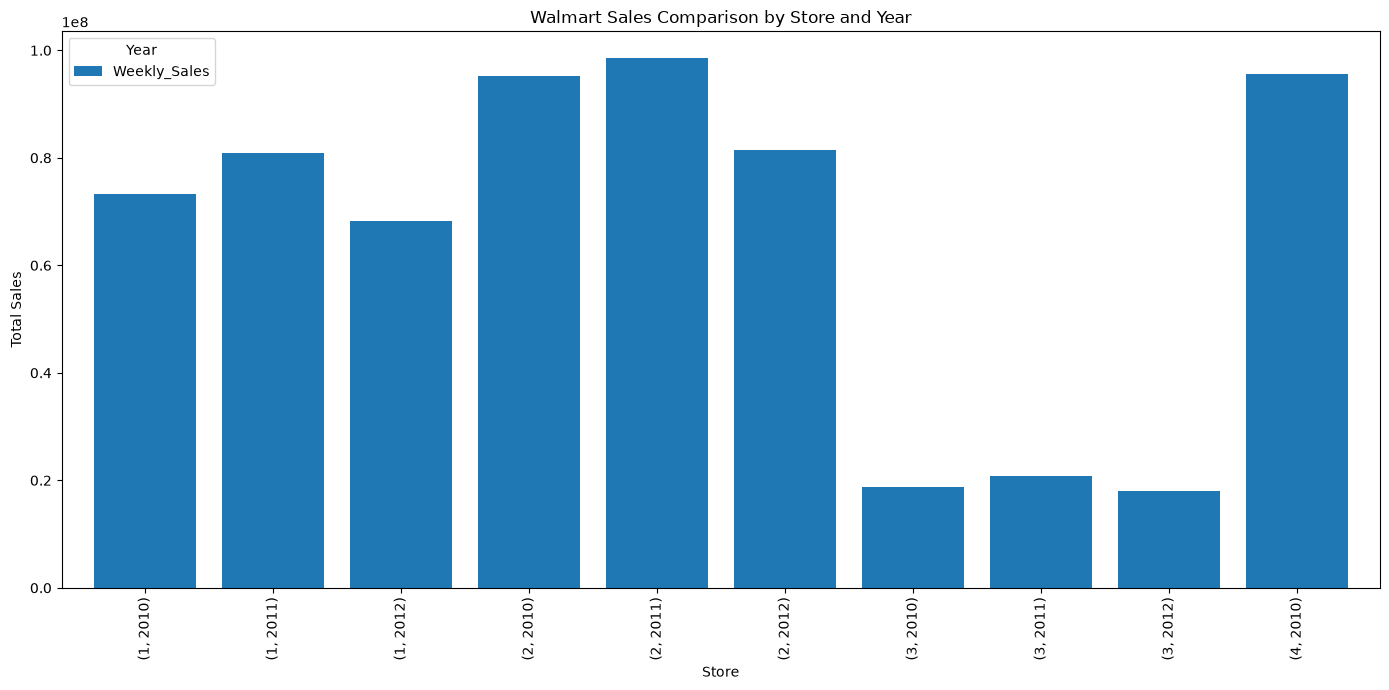

In [29]:
# Multiple bar chart
less_data=yearly_sales.head(10)
ax = less_data.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title("Walmart Sales Comparison by Store and Year")
plt.xlabel("Store")
plt.ylabel("Total Sales")
plt.legend(title="Year")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [32]:
## Task 5: Stacked Bar chart:
df["Holiday_Type"] = df["Holiday_Flag"].map({
    0: "Non-Holiday",
    1: "Holiday"
})

holiday_sales = df.groupby(
    ["Store", "Holiday_Type"]
)["Weekly_Sales"].sum().unstack(fill_value=0)
print(holiday_sales)


Holiday_Type      Holiday   Non-Holiday
Store                                  
1             16657476.56  2.057453e+08
2             20792669.00  2.545898e+08
3              4378110.50  5.320862e+07
4             22431026.24  2.771129e+08
5              3595016.07  4.188067e+07
6             16809079.27  2.069471e+08
7              6724002.65  7.487427e+07
8              9753308.60  1.201979e+08
9              5889508.21  7.189971e+07
10            21137559.49  2.504802e+08
11            14483944.85  1.794788e+08
12            11381404.20  1.329058e+08
13            21130438.06  2.653873e+08
14            21205829.98  2.677941e+08
15             7064060.18  8.206962e+07
16             5667336.46  6.858509e+07
17             9797969.71  1.179842e+08
18            11694221.61  1.434205e+08
19            15770467.34  1.908644e+08
20            22490350.81  2.789074e+08
21             8264913.09  9.985297e+07
22            10848746.56  1.362269e+08
23            14625422.94  1.841252e+08


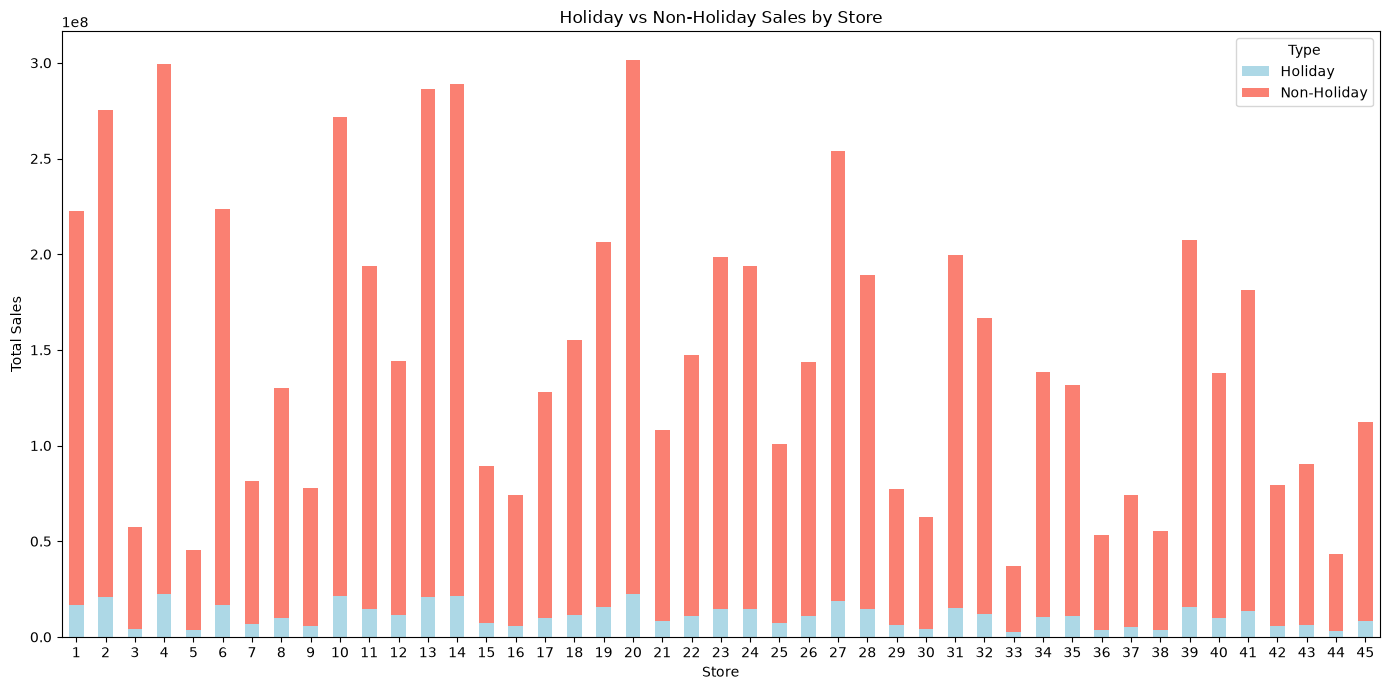

In [33]:

holiday_sales.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7),
    color=["lightblue", "salmon"]
)

plt.title("Holiday vs Non-Holiday Sales by Store")
plt.xlabel("Store")
plt.ylabel("Total Sales")
plt.legend(title="Type")
plt.xticks(rotation=0)
plt.tight_layout()


Text(0, 0.5, 'Frequency')

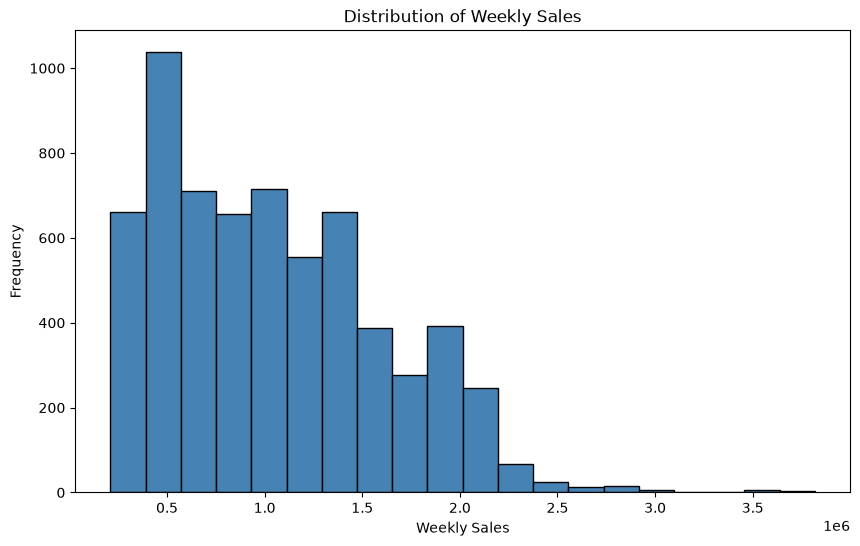

In [34]:
## Task 6: Histogram
plt.figure(figsize=(10, 6))

plt.hist(
    df["Weekly_Sales"],
    bins=20,
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribution of Weekly Sales")
plt.xlabel("Weekly Sales")
plt.ylabel("Frequency")


Text(0.5, 1.0, 'Walmart Store Sales Market Share')

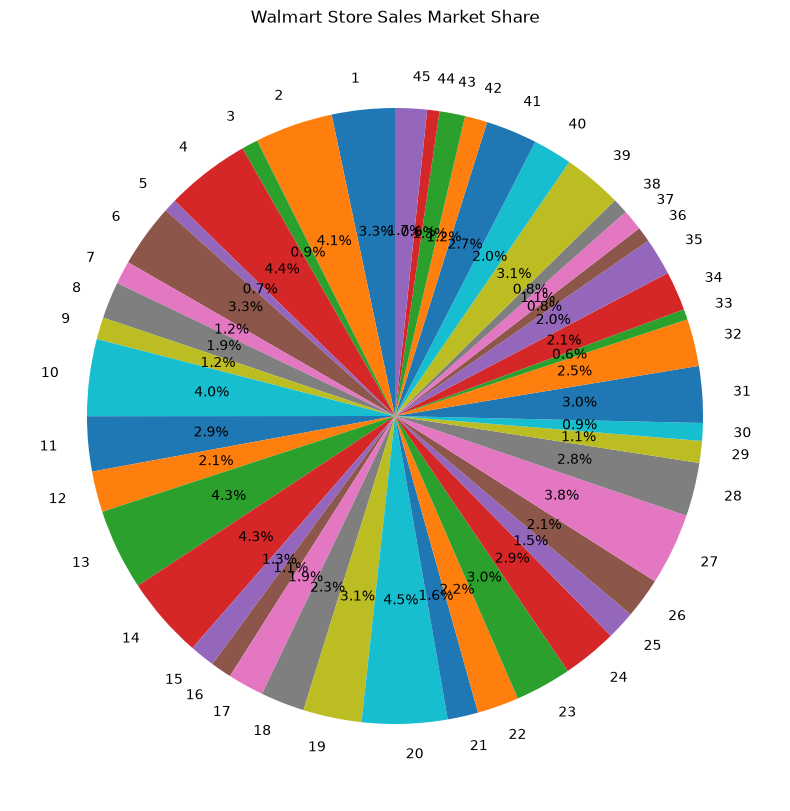

In [35]:
## Task 7: Pie Chart
plt.figure(figsize=(10, 10))

plt.pie(
    store_sales,
    labels=store_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Walmart Store Sales Market Share")